# Taco Bueno — Economía: interpretación y evaluación de promociones

**¿qué significan los patrones encontrados en el análisis exploratorio para el negocio, y cómo evaluaríamos una promoción en la siguiente fase?**

**Estructura del notebook** 

| Sección | Herramienta | Qué hace |
|---|---|---|
| 0–2 | PySpark | Valida definiciones de la tabla limpia y construye tablas **agregadas** (tienda-día, celdas de tickets, artículos). El trabajo pesado se queda en Spark. |
| 3 | pandas | Descompone el cambio en ingresos (tickets, unidades, precio puro, mezcla, descuentos). → `resumen_negocio.png` |
| 4 | pyfixest | Compara tickets con y sin descuento, primero sin controles y luego con efectos fijos. → `impacto_promociones.png` |
| 5 | pandas | Muestra que los descuentos no se aplican al azar (factores de confusión). → `factores_confusion.png` |
| 6 | pyfixest | Dispersión de precios entre tiendas y una elasticidad exploratoria. |
| 7–10 | Python / texto | Síntesis con cifras, hipótesis, propuesta de evaluación, datos adicionales y limitaciones. |

**Filtros requeridos (siempre):** `is_incomplete_store = 0` y `menu_price > 0`, sobre `workspace.default.taco_bueno_clean`.

`pyfixest`: mismas regresiones con efectos fijos y errores agrupados. Las tablas agregadas también se guardan en `outputs/data/`, y `05_economia_local.R` reproduce el análisis en R con esos archivos si se necesita entregar esa versión.

In [0]:
%pip install -q pyfixest

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


## 0. Configuración

In [0]:
from pyspark.sql import functions as F
import os

TABLA = "workspace.default.taco_bueno_clean"
df = spark.table(TABLA)

# Carpeta de resultados: outputs/ junto a este notebook
try:
    nb_path = dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get()
    OUT_DIR = "/Workspace" + os.path.dirname(nb_path) + "/outputs"
except Exception:
    OUT_DIR = os.path.join(os.getcwd(), "outputs")
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print("Resultados en:", OUT_DIR)

Resultados en: /Workspace/Users/a01663116@tec.mx/Taco Bueno/Week 4/05 Economic Analysis/outputs


## 1. Validación de definiciones

Antes de agregar hay que confirmar tres cosas, porque de ellas dependen todos los cálculos:

1. Si `menu_price` y `net_item_price` son el **total de la línea** o el **precio unitario** (se prueba en líneas con `quantity > 1`).
2. Si `net_item_price = menu_price − item_discount`.
3. Si los campos de ticket (`net_total`, `total_discount`) se repiten en cada renglón y cuadran con la suma de los artículos.

**Decisiones:** un ticket se identifica con `store_number + order_date + check_number`; se excluyen artículos anulados (`is_voided = 1`) y tickets con total negativo (`is_negative_total = 1`).

In [0]:
base = df.filter((F.col("is_incomplete_store") == 0) & (F.col("menu_price") > 0))

print(f"Filas totales: {df.count():,}")
print(f"Filas con filtros requeridos: {base.count():,}")

for c in ["transaction_type", "channel", "time_period", "net_total_status", "is_voided", "has_discount"]:
    print(f"\n--- {c} ---")
    base.groupBy(c).count().orderBy(F.desc("count")).show(15, truncate=False)

base.select(
    F.min("item_discount"), F.max("item_discount"),
    F.min("total_discount"), F.max("total_discount"),
    F.min("quantity"), F.max("quantity"),
).show()

Filas totales: 42,253,092
Filas con filtros requeridos: 22,502,502

--- transaction_type ---
+----------------+--------+
|transaction_type|count   |
+----------------+--------+
|Regular Sale    |22492690|
|Discount        |9812    |
+----------------+--------+


--- channel ---
+----------------+--------+
|channel         |count   |
+----------------+--------+
|Drive Thru      |14782670|
|Dine-In         |3701903 |
|Carry Out       |1651171 |
|Online: DoorDash|1502661 |
|Online: UberEats|456631  |
|Online          |157550  |
|To Go           |133943  |
|Inside          |48093   |
|Online: GrubHub |43428   |
|3               |15612   |
|Mobile          |5893    |
|Online: Zipline |2947    |
+----------------+--------+


--- time_period ---
+-----------+-------+
|time_period|count  |
+-----------+-------+
|Lunch      |7276280|
|Dinner     |7109734|
|Afternoon  |5044688|
|Breakfast  |2733718|
|Late Night |338082 |
+-----------+-------+


--- net_total_status ---
+-------------------+-----

In [0]:
# ¿Precios a nivel línea o unitarios? Se prueba en líneas con más de una unidad
q2 = base.filter((F.col("quantity") > 1) & F.col("price_per_unit").isNotNull())
cerca = lambda a, b: (F.abs(a - b) < 0.02).cast("double")
chk = q2.select(
    F.count("*").alias("lineas_qty_mayor_1"),
    F.avg(cerca(F.col("menu_price"), F.col("price_per_unit") * F.col("quantity"))).alias("menu_price_es_total_linea"),
    F.avg(cerca(F.col("menu_price"), F.col("price_per_unit"))).alias("menu_price_es_unitario"),
    F.avg(cerca(F.col("net_item_price"), F.col("price_per_unit") * F.col("quantity"))).alias("net_item_es_total_linea"),
).first().asDict()
print(chk)

LINE_LEVEL = (chk["menu_price_es_total_linea"] or 0) >= (chk["menu_price_es_unitario"] or 0)
print("Precios a nivel línea:", LINE_LEVEL)

# ¿net_item_price = menu_price − item_discount?
(base.filter(F.abs(F.col("item_discount")) > 0)
     .select(F.avg(cerca(F.col("net_item_price"),
                         F.col("menu_price") - F.abs(F.col("item_discount")))).alias("identidad_neto"))
     .show())

{'lineas_qty_mayor_1': 46698, 'menu_price_es_total_linea': 0.002698188359244507, 'menu_price_es_unitario': 0.9483489656944623, 'net_item_es_total_linea': 1.0}
Precios a nivel línea: False
+------------------+
|    identidad_neto|
+------------------+
|0.7537708927843457|
+------------------+



In [0]:
# ¿Cuadran los artículos con los totales del ticket? (muestra de ~2% de los tickets)
muestra = (df.filter(F.col("is_incomplete_store") == 0)
             .filter(F.abs(F.hash("check_number")) % 50 == 0))
linea_neta = F.col("net_item_price") if LINE_LEVEL else F.col("net_item_price") * F.col("quantity")
rec = (muestra.groupBy("store_number", "order_date", "check_number")
       .agg(F.sum(linea_neta).alias("suma_items"),
            F.max("net_total").alias("net_total"),
            F.sum(F.abs("item_discount")).alias("suma_desc_items"),
            F.max(F.abs("total_discount")).alias("total_discount"))
       .filter(F.col("net_total").isNotNull()))
rec.select(
    F.count("*").alias("tickets_muestra"),
    F.avg(cerca(F.col("suma_items"), F.col("net_total"))).alias("items_cuadran_con_net_total"),
    F.avg(cerca(F.col("suma_desc_items"), F.col("total_discount"))).alias("desc_items_cuadran_con_total_discount"),
    F.avg((F.col("total_discount") > 0).cast("double")).alias("pct_tickets_con_total_discount"),
).show()

+---------------+---------------------------+-------------------------------------+------------------------------+
|tickets_muestra|items_cuadran_con_net_total|desc_items_cuadran_con_total_discount|pct_tickets_con_total_discount|
+---------------+---------------------------+-------------------------------------+------------------------------+
|         119218|          0.922788505091513|                   0.9281652099515174|           0.07238839772517573|
+---------------+---------------------------+-------------------------------------+------------------------------+



**Cómo se usan estas pruebas:** el ingreso bruto de un ticket es la suma de `menu_price` de sus artículos; el descuento del ticket es el **mayor** entre la suma de descuentos por artículo y `total_discount` (así se capturan también los descuentos que se registran a nivel ticket y no por artículo); el ingreso neto es bruto − descuento. Un ticket "tiene descuento" si ese monto es positivo o si algún artículo tiene `has_discount = 1`.

## 2. Construcción de tablas agregadas

In [0]:
GROSS = F.col("menu_price") if LINE_LEVEL else F.col("menu_price") * F.col("quantity")
REV   = F.col("net_item_price") if LINE_LEVEL else F.col("net_item_price") * F.col("quantity")

lineas = (base
    .filter((F.col("is_voided") == 0) & (F.col("is_negative_total") == 0) & (F.col("quantity") > 0))
    .withColumn("ticket_id", F.concat_ws("|", "store_number", F.col("order_date").cast("string"), "check_number"))
    .withColumn("gross", GROSS)
    .withColumn("rev", REV)
    .withColumn("desc_linea", F.greatest(F.col("gross") - F.col("rev"), F.lit(0.0)))
    .withColumn("periodo", F.trunc("order_date", "month")))

tickets = (lineas.groupBy("ticket_id").agg(
        F.first("store_number").alias("store_number"),
        F.first("order_date").alias("order_date"),
        F.first("time_period").alias("time_period"),
        F.first("channel").alias("channel"),
        F.sum("gross").alias("gross"),
        F.sum("desc_linea").alias("desc_items"),
        F.max(F.abs(F.coalesce("total_discount", F.lit(0.0)))).alias("desc_ticket"),
        F.max("has_discount").alias("algun_item_desc"),
        F.sum("quantity").alias("units"))
    .withColumn("descuento", F.least(F.greatest("desc_items", "desc_ticket"), F.col("gross")))
    .withColumn("rev", F.col("gross") - F.col("descuento"))
    .withColumn("con_desc", ((F.col("descuento") > 0.005) | (F.col("algun_item_desc") == 1)).cast("int")))

# cache() no existe en serverless; si falla, se sigue sin caché
try:
    lineas = lineas.cache(); tickets = tickets.cache()
except Exception as e:
    print("Sin caché:", type(e).__name__)

print(f"Tickets válidos: {tickets.count():,}")

Sin caché: AnalysisException
Tickets válidos: 5,979,730


In [0]:
def exportar(sdf, nombre):
    pdf = sdf.toPandas()
    pdf.to_csv(os.path.join(DATA_DIR, nombre), index=False)
    print(f"{nombre:<24} {len(pdf):>10,} filas")

suma = lambda c: F.sum(c).alias(c)

# 1) Tienda-día: base del resumen de negocio
exportar(tickets.groupBy("store_number", "order_date").agg(
    suma("rev"), suma("gross"), suma("descuento"), suma("units"),
    F.count("*").alias("tickets"), F.sum("con_desc").alias("tickets_desc")), "tienda_dia.csv")

# 2) Celdas tienda × día × franja × con/sin descuento: base de las regresiones
exportar(tickets.groupBy("store_number", "order_date", "time_period", "con_desc").agg(
    F.count("*").alias("n_tickets"), suma("rev"), suma("gross"), suma("descuento"), suma("units")),
    "celdas_ticket.csv")

# 3) Canal × franja × con/sin descuento
exportar(tickets.groupBy("channel", "time_period", "con_desc").agg(
    F.count("*").alias("n_tickets"), suma("rev"), suma("gross"), suma("descuento"), suma("units")),
    "canal_franja.csv")

# 4) Artículo × mes: índice de precios
exportar(lineas.groupBy("menu_item", "report_group", "item_category", "periodo").agg(
    suma("rev"), suma("gross"), F.sum("quantity").alias("units"),
    F.countDistinct("store_number").alias("n_tiendas")), "item_mes.csv")

# 5) Tienda × artículo × mes para los 40 artículos con más ventas: dispersión y elasticidad
top = (lineas.groupBy("menu_item").agg(F.sum("gross").alias("g"))
       .orderBy(F.desc("g")).limit(40).select("menu_item"))
exportar(lineas.join(F.broadcast(top), "menu_item")
         .groupBy("store_number", "menu_item", "periodo")
         .agg(suma("rev"), suma("gross"), F.sum("quantity").alias("units")), "item_tienda_mes.csv")

tienda_dia.csv               28,841 filas
celdas_ticket.csv           230,054 filas
canal_franja.csv                 99 filas
item_mes.csv                  1,637 filas
item_tienda_mes.csv          43,750 filas


## 3. Resumen de negocio: ¿de dónde viene el cambio en ingresos?

A partir de aquí todo se calcula sobre las tablas agregadas, así que estas celdas se pueden volver a correr sin repetir las secciones 1–2.

El ingreso neto por tienda-día se puede escribir como un producto exacto:

$$\frac{R}{TD} = \underbrace{\frac{T}{TD}}_{\text{tickets}} \times \underbrace{\frac{Q}{T}}_{\text{unidades/ticket}} \times \underbrace{P^{F}}_{\text{precio puro}} \times \underbrace{\frac{G/Q}{P^{F}}}_{\text{mezcla}} \times \underbrace{\frac{R}{G}}_{1-\text{tasa de descuento}}$$

donde $G$ es el ingreso a precio de lista y $P^F$ un índice de precios Fisher encadenado (compara el precio de **los mismos artículos** mes contra mes). Al tomar logaritmos, el cambio en ingresos se reparte sin residuo entre cinco componentes. Esto responde la pregunta central: **¿el negocio crece porque llega más gente, porque compran más, porque subieron los precios o porque cambió lo que se vende?**

Para que la composición de tiendas no contamine la comparación se usa un **panel balanceado**: tiendas con al menos 15 días de datos en cada mes completo (≥ 20 días con datos).

In [0]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pyfixest as pf

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)

def leer(nombre, fechas=()):
    return pd.read_csv(os.path.join(DATA_DIR, nombre), dtype={"store_number": str}, parse_dates=list(fechas))

tienda_dia      = leer("tienda_dia.csv", ["order_date"])
celdas          = leer("celdas_ticket.csv", ["order_date"])
canal           = leer("canal_franja.csv")
item_mes        = leer("item_mes.csv", ["periodo"])
item_tienda_mes = leer("item_tienda_mes.csv", ["periodo"])

AZUL, NARANJA, GRIS, VERDE, MORADO = "#1F4E79", "#C55A11", "#8C8C8C", "#548235", "#7030A0"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
})
FUENTE = "Fuente: workspace.default.taco_bueno_clean (is_incomplete_store = 0, menu_price > 0)."
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
PCT = mtick.PercentFormatter(1.0, decimals=0)

def guardar(fig, nombre):
    fig.savefig(os.path.join(OUT_DIR, nombre), dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

def wmean(x, w):
    return float(np.sum(x * w) / np.sum(w))

print({k: len(v) for k, v in [("tienda_dia", tienda_dia), ("celdas", celdas), ("canal", canal),
                               ("item_mes", item_mes), ("item_tienda_mes", item_tienda_mes)]})

{'tienda_dia': 28841, 'celdas': 230054, 'canal': 99, 'item_mes': 1637, 'item_tienda_mes': 43750}


In [0]:
tienda_dia["periodo"] = tienda_dia["order_date"].dt.to_period("M").dt.to_timestamp()

cobertura = (tienda_dia.groupby("periodo")
             .agg(dias=("order_date", "nunique"), tiendas=("store_number", "nunique")).reset_index())
display(cobertura)
meses_completos = sorted(cobertura.loc[cobertura["dias"] >= 20, "periodo"])

dias_tm = tienda_dia.groupby(["store_number", "periodo"]).size().rename("dias_tienda").reset_index()
ok = (dias_tm[dias_tm["periodo"].isin(meses_completos) & (dias_tm["dias_tienda"] >= 15)]
      .groupby("store_number").size())
tiendas_bal = ok[ok == len(meses_completos)].index.tolist()
if len(tiendas_bal) < 20:
    print("Aviso: panel balanceado muy pequeño; se usan todas las tiendas")
    tiendas_bal = tienda_dia["store_number"].unique().tolist()
print(f"Meses completos: {len(meses_completos)} ({meses_completos[0]:%b %Y} a {meses_completos[-1]:%b %Y}) | "
      f"Tiendas en panel balanceado: {len(tiendas_bal)} de {tienda_dia['store_number'].nunique()}")

mes = (tienda_dia[tienda_dia["periodo"].isin(meses_completos) & tienda_dia["store_number"].isin(tiendas_bal)]
       .groupby("periodo")
       .agg(tienda_dias=("store_number", "size"), ingreso=("rev", "sum"), bruto=("gross", "sum"),
            descuento=("descuento", "sum"), unidades=("units", "sum"), tickets=("tickets", "sum"),
            tickets_desc=("tickets_desc", "sum"))
       .reset_index())
mes = mes.assign(
    ingreso_td=mes.ingreso / mes.tienda_dias, tickets_td=mes.tickets / mes.tienda_dias,
    unid_ticket=mes.unidades / mes.tickets, precio_lista_u=mes.bruto / mes.unidades,
    ingreso_u=mes.ingreso / mes.unidades, ticket_prom=mes.ingreso / mes.tickets,
    tasa_desc=mes.descuento / mes.bruto, pct_tickets_desc=mes.tickets_desc / mes.tickets)
display(mes[["periodo", "ingreso_td", "tickets_td", "unid_ticket", "precio_lista_u",
             "ticket_prom", "tasa_desc", "pct_tickets_desc"]])

periodo,dias,tiendas
2025-12-01T00:00:00.000Z,1,112
2026-01-01T00:00:00.000Z,26,113
2026-02-01T00:00:00.000Z,25,113
2026-03-01T00:00:00.000Z,29,113
2026-04-01T00:00:00.000Z,29,113
2026-05-01T00:00:00.000Z,31,113
2026-06-01T00:00:00.000Z,30,113
2026-07-01T00:00:00.000Z,29,113
2026-08-01T00:00:00.000Z,29,113
2026-09-01T00:00:00.000Z,27,113


Meses completos: 9 (Jan 2026 a Sep 2026) | Tiendas en panel balanceado: 112 de 113


periodo,ingreso_td,tickets_td,unid_ticket,precio_lista_u,ticket_prom,tasa_desc,pct_tickets_desc
2026-01-01T00:00:00.000Z,2584.2347928994086,191.7274625826662,3.777838292186561,3.6268537760012456,13.478688749584721,0.01627380991899814,0.06418823854053769
2026-02-01T00:00:00.000Z,2824.1442959256615,214.50679056468906,3.6015445109048803,3.71699393646683,13.16575707692564,0.01652075658508694,0.06525766840500508
2026-03-01T00:00:00.000Z,2897.792638888889,219.0787037037037,3.650017258017934,3.684561070418556,13.227176306502399,0.01647259581891014,0.06629332995217063
2026-04-01T00:00:00.000Z,2906.086380160197,218.52248921749845,3.752801258663178,3.6074843573437843,13.298797714443612,0.017681421486492762,0.06854695456519165
2026-05-01T00:00:00.000Z,2808.6858369346014,209.2607317775857,3.799389820801163,3.6011853653198367,13.421944065071097,0.01902917061911835,0.07305078585353496
2026-06-01T00:00:00.000Z,2822.9751477170994,208.723664577738,3.8212452086189814,3.6111512755803576,13.52494051610376,0.019867535012464594,0.07467048309130396
2026-07-01T00:00:00.000Z,2821.0186976600985,199.14778325123152,3.8098269720731195,3.7961234102092343,14.165453672669257,0.020544039951874187,0.07600427931827738
2026-08-01T00:00:00.000Z,2849.9826911220716,202.25030826140568,3.7748331047096477,3.8141859021879396,14.091363892699283,0.021291368500374254,0.07815576893766195
2026-09-01T00:00:00.000Z,2846.3073611111113,203.51455026455025,3.752375582521432,3.811382473692438,13.985768375829505,0.0220931289886756,0.07897430731133455


In [0]:
# Índice de precios Fisher encadenado: mismo artículo, mes contra mes, a precio de lista
def indice_fisher(im, meses, min_q=100):
    filas = [dict(periodo=meses[0], fisher=1.0, laspeyres=1.0, paasche=1.0, cobertura=np.nan)]
    for t0, t1 in zip(meses[:-1], meses[1:]):
        a = im[im["periodo"] == t0].assign(p0=lambda x: x.gross / x.units)[["menu_item", "p0", "units"]].rename(columns={"units": "q0"})
        b = im[im["periodo"] == t1].assign(p1=lambda x: x.gross / x.units)[["menu_item", "p1", "units"]].rename(columns={"units": "q1"})
        m = a.merge(b, on="menu_item")
        m = m[(m.q0 >= min_q) & (m.q1 >= min_q)]
        L = (m.p1 * m.q0).sum() / (m.p0 * m.q0).sum()
        P = (m.p1 * m.q1).sum() / (m.p0 * m.q1).sum()
        filas.append(dict(periodo=t1, fisher=np.sqrt(L * P), laspeyres=L, paasche=P,
                          cobertura=(m.p1 * m.q1).sum() / (b.p1 * b.q1).sum()))
    return pd.DataFrame(filas)

precios = indice_fisher(item_mes, meses_completos)
display(precios)   # cobertura = % del ingreso del mes que entra en la comparación

d = mes.merge(precios[["periodo", "fisher"]], on="periodo").sort_values("periodo").reset_index(drop=True)
d["d_ingreso"] = np.log(d.ingreso_td).diff()
d["d_tickets"] = np.log(d.tickets_td).diff()
d["d_unid"]    = np.log(d.unid_ticket).diff()
d["d_precio"]  = np.log(d.fisher).where(d.index > 0)
d["d_mezcla"]  = np.log(d.precio_lista_u).diff() - d["d_precio"]
d["d_desc"]    = np.log(1 - d.tasa_desc).diff()
residuo = d.d_ingreso - d[["d_tickets", "d_unid", "d_precio", "d_mezcla", "d_desc"]].sum(axis=1, min_count=5)
assert residuo.abs().max(skipna=True) < 1e-8, "La descomposición no cuadra"   # identidad exacta
descomp = d
display((descomp[["periodo"] + [c for c in d.columns if c.startswith("d_")]]
         .set_index("periodo") * 100).round(2))

acum = descomp[[c for c in d.columns if c.startswith("d_")]].sum()
componentes = pd.DataFrame({
    "componente": ["Tickets por tienda-día", "Unidades por ticket", "Precio de lista (puro)",
                   "Mezcla de productos", "Descuentos"],
    "pct": 100 * acum[["d_tickets", "d_unid", "d_precio", "d_mezcla", "d_desc"]].values})
display(componentes)

periodo,fisher,laspeyres,paasche,cobertura
2026-01-01T00:00:00.000Z,1.0,1.0,1.0,null
2026-02-01T00:00:00.000Z,0.9767656457835681,0.9918636588162318,0.9618974526414793,0.9982032327935955
2026-03-01T00:00:00.000Z,0.9990974300233669,0.9995233489575642,0.9986716925826172,0.9939279582701599
2026-04-01T00:00:00.000Z,0.9994366790150541,0.9994536004454325,0.9994197578711671,0.9993412613249846
2026-05-01T00:00:00.000Z,0.998742123017061,0.9987410805120458,0.9987431655231643,0.9985389547563432
2026-06-01T00:00:00.000Z,1.0038934192937474,1.0039886680451058,1.0037981795786712,0.9979437182182317
2026-07-01T00:00:00.000Z,1.052756128703553,1.0529660119151558,1.0525462873270732,0.9912775734270303
2026-08-01T00:00:00.000Z,1.00677819468436,1.0066317435108012,1.0069246671645649,0.9888421272773747
2026-09-01T00:00:00.000Z,1.0012046989564063,1.0011988037747512,1.0012105941727727,0.9976906550002753


d_ingreso,d_tickets,d_unid,d_precio,d_mezcla,d_desc
null,null,null,null,null,null
8.88,11.23,-4.78,-2.35,4.81,-0.03
2.57,2.11,1.34,-0.09,-0.79,0.0
0.29,-0.25,2.78,-0.06,-2.06,-0.12
-3.41,-4.33,1.23,-0.13,-0.05,-0.14
0.51,-0.26,0.57,0.39,-0.11,-0.09
-0.07,-4.7,-0.3,5.14,-0.15,-0.07
1.02,1.55,-0.92,0.68,-0.2,-0.08
-0.13,0.62,-0.6,0.12,-0.19,-0.08


componente,pct
Tickets por tienda-día,5.9662604481466985
Unidades por ticket,-0.6762837586165471
Precio de lista (puro),3.7023116110858636
Mezcla de productos,1.2603317123445743
Descuentos,-0.5933154631433905


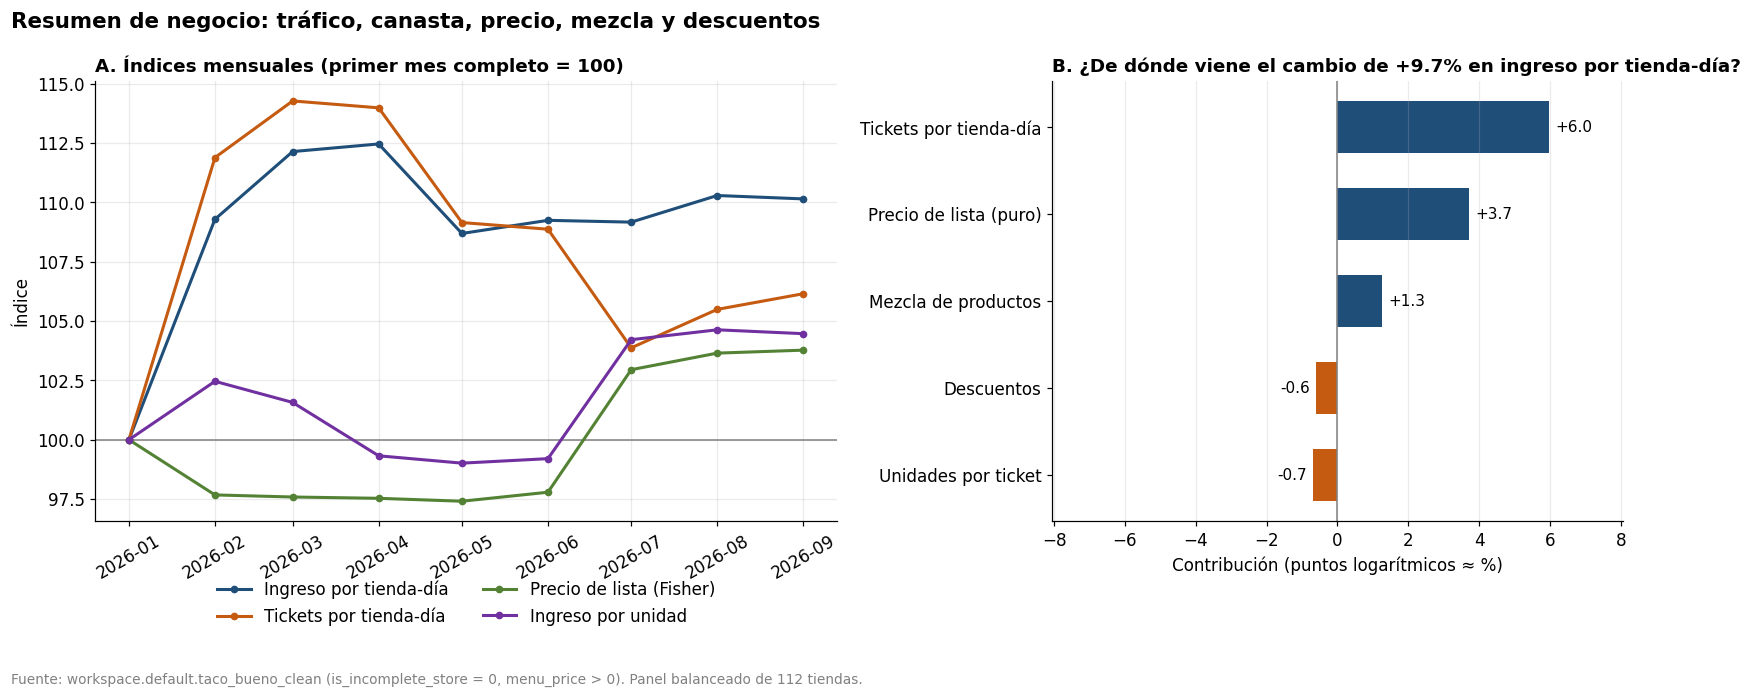

In [0]:
precio_puro = descomp.fisher.cumprod()
series = {
    "Ingreso por tienda-día":   (descomp.ingreso_td, AZUL),
    "Tickets por tienda-día":   (descomp.tickets_td, NARANJA),
    "Precio de lista (Fisher)": (precio_puro, VERDE),
    "Ingreso por unidad":       (descomp.ingreso_u, MORADO),
}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})

ax1.axhline(100, color="grey", lw=1)
for nombre, (s, color) in series.items():
    ax1.plot(descomp.periodo, 100 * s / s.iloc[0], marker="o", ms=4, lw=2, color=color, label=nombre)
ax1.set_title("A. Índices mensuales (primer mes completo = 100)")
ax1.set_ylabel("Índice")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax1.tick_params(axis="x", labelrotation=30)

c = componentes.sort_values("pct")
colores = [AZUL if v >= 0 else NARANJA for v in c.pct]
ax2.barh(c.componente, c.pct, color=colores, height=0.6)
ax2.axvline(0, color="grey", lw=1)
rango = max(c.pct.abs().max(), 0.5)
for y, v in enumerate(c.pct):
    ax2.text(v + (0.03 if v >= 0 else -0.03) * rango, y, f"{v:+.1f}", va="center",
             ha="left" if v >= 0 else "right", fontsize=10)
ax2.set_xlim(-1.35 * rango, 1.35 * rango)
ax2.grid(axis="y", visible=False)
ax2.set_title(f"B. ¿De dónde viene el cambio de {100 * acum.d_ingreso:+.1f}% en ingreso por tienda-día?")
ax2.set_xlabel("Contribución (puntos logarítmicos ≈ %)")

fig.suptitle("Resumen de negocio: tráfico, canasta, precio, mezcla y descuentos",
             x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.text(0.01, -0.04, f"{FUENTE} Panel balanceado de {len(tiendas_bal)} tiendas.", color="grey", fontsize=9)
fig.tight_layout()
guardar(fig, "resumen_negocio.png")

**Cómo leerlo.** Si la barra de *precio de lista* domina, el crecimiento es inflación de menú y no más clientes; si dominan *tickets*, hay más tráfico. La barra de *mezcla* separa "subió el precio" de "la gente compra artículos más caros", algo que el precio promedio por unidad mezcla. La barra de *descuentos* mide cuánto ingreso se pierde por un aumento (o se gana por una caída) de la tasa de descuento.

### Interpretación: resumen de negocio

Entre enero y septiembre de 2026, en un panel balanceado de **112 tiendas**, el ingreso neto por tienda-día creció **+9.7%**. La descomposición muestra de dónde viene ese crecimiento:

| Componente | Aporte (puntos) | Qué significa |
|---|---|---|
| Tickets por tienda-día | **+6.0** | Llegaron más clientes: es el motor principal (≈ 60% del crecimiento) |
| Precio de lista puro | **+3.7** | Aumentos de precio del menú, medidos sobre los mismos productos |
| Mezcla de productos | +1.3 | Los clientes compran productos un poco más caros |
| Unidades por ticket | −0.7 | Cada cliente compra ligeramente menos artículos |
| Descuentos | −0.6 | Se pierde un poco más de ingreso por descuentos que en enero |

**Conclusión:** el crecimiento de Taco Bueno se explica principalmente por **más tráfico**, no por subir precios. El aumento de precios sí contribuye, pero es secundario. La canasta por cliente no crece: llega más gente, pero cada uno compra casi lo mismo.

**Advertencia:** la comparación es de enero contra septiembre. Enero suele ser un mes bajo para restaurantes, así que parte del aumento en tickets puede ser **estacionalidad** y no una tendencia. Para separarlo se necesitarían datos del mismo periodo del año anterior.

## 4. Tickets con y sin descuento

La comparación ingenua (promedio de tickets con descuento vs. sin descuento) mezcla el efecto del descuento con **dónde y cuándo** se usa. Por eso se estima la misma diferencia agregando controles uno por uno, con regresiones ponderadas por número de tickets sobre celdas tienda × día × franja horaria (equivalente a la regresión a nivel ticket con esos controles) y errores agrupados por tienda:

1. Sin controles → 2. + franja horaria → 3. + tienda → 4. + fecha → 5. misma tienda y mismo día.

Si el coeficiente cambia mucho entre especificaciones, la diferencia ingenua está contaminada por factores de confusión. **Ninguna especificación es causal**: los clientes eligen usar el descuento, y muchos descuentos exigen comprar más (combos, mínimos de compra).

In [0]:
g = celdas.assign(t_rev=celdas.rev, t_gross=celdas.gross).groupby("con_desc").agg(
    tickets=("n_tickets", "sum"), rev=("rev", "sum"), gross=("gross", "sum"),
    units=("units", "sum"), descuento=("descuento", "sum"))
resumen_desc = pd.DataFrame({
    "tickets": g.tickets, "pct_tickets": g.tickets / g.tickets.sum(),
    "ticket_neto": g.rev / g.tickets, "ticket_bruto": g.gross / g.tickets,
    "unid_ticket": g.units / g.tickets, "desc_por_ticket": g.descuento / g.tickets,
    "tasa_desc": g.descuento / g.gross})
display(resumen_desc)

pct_tickets_desc = wmean(celdas.con_desc, celdas.n_tickets)
pct_desc_bruto   = celdas.descuento.sum() / celdas.gross.sum()
desc_prom        = resumen_desc.loc[1, "desc_por_ticket"] if 1 in resumen_desc.index else np.nan
print(f"Tickets con descuento: {100 * pct_tickets_desc:.1f}% | Descuento total = {100 * pct_desc_bruto:.2f}% "
      f"del ingreso a precio de lista | Descuento promedio por ticket con descuento: ${desc_prom:.2f}")

tickets,pct_tickets,ticket_neto,ticket_bruto,unid_ticket,desc_por_ticket,tasa_desc
5546777,0.9275965637244491,13.872200427383325,13.872200427383325,3.762349378747334,0.0,0.0
432953,0.0724034362755509,9.857528415324527,13.494425214746173,3.5694359433933935,3.636896799421646,0.26951105671750947


Tickets con descuento: 7.2% | Descuento total = 1.90% del ingreso a precio de lista | Descuento promedio por ticket con descuento: $3.64


/local_disk0/.ephemeral_nfs/envs/pythonEnv-5238ef6c-f757-4c19-837a-9f08c787804f/lib/python3.12/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 4 singleton fixed effect(s) dropped from the model.
  warnings.warn(
/local_disk0/.ephemeral_nfs/envs/pythonEnv-5238ef6c-f757-4c19-837a-9f08c787804f/lib/python3.12/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 4 singleton fixed effect(s) dropped from the model.
  warnings.warn(
/local_disk0/.ephemeral_nfs/envs/pythonEnv-5238ef6c-f757-4c19-837a-9f08c787804f/lib/python3.12/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 4 singleton fixed effect(s) dropped from the model.
  warnings.warn(


variable,especificacion,coef,se,base,pct,lo,hi
ticket_neto,1. Sin controles,-4.015,0.138,13.872,-28.94,-30.892,-26.989
ticket_neto,2. + franja horaria,-3.909,0.138,13.872,-28.177,-30.124,-26.229
ticket_neto,3. + tienda,-3.966,0.134,13.872,-28.592,-30.479,-26.705
ticket_neto,4. + fecha,-3.99,0.133,13.872,-28.762,-30.644,-26.879
ticket_neto,5. Misma tienda y día,-3.997,0.134,13.872,-28.812,-30.699,-26.925
ticket_bruto,1. Sin controles,-0.378,0.139,13.872,-2.723,-4.683,-0.764
ticket_bruto,2. + franja horaria,-0.27,0.137,13.872,-1.943,-3.882,-0.005
ticket_bruto,3. + tienda,-0.308,0.135,13.872,-2.224,-4.13,-0.317
ticket_bruto,4. + fecha,-0.333,0.135,13.872,-2.404,-4.314,-0.494
ticket_bruto,5. Misma tienda y día,-0.334,0.136,13.872,-2.408,-4.336,-0.481


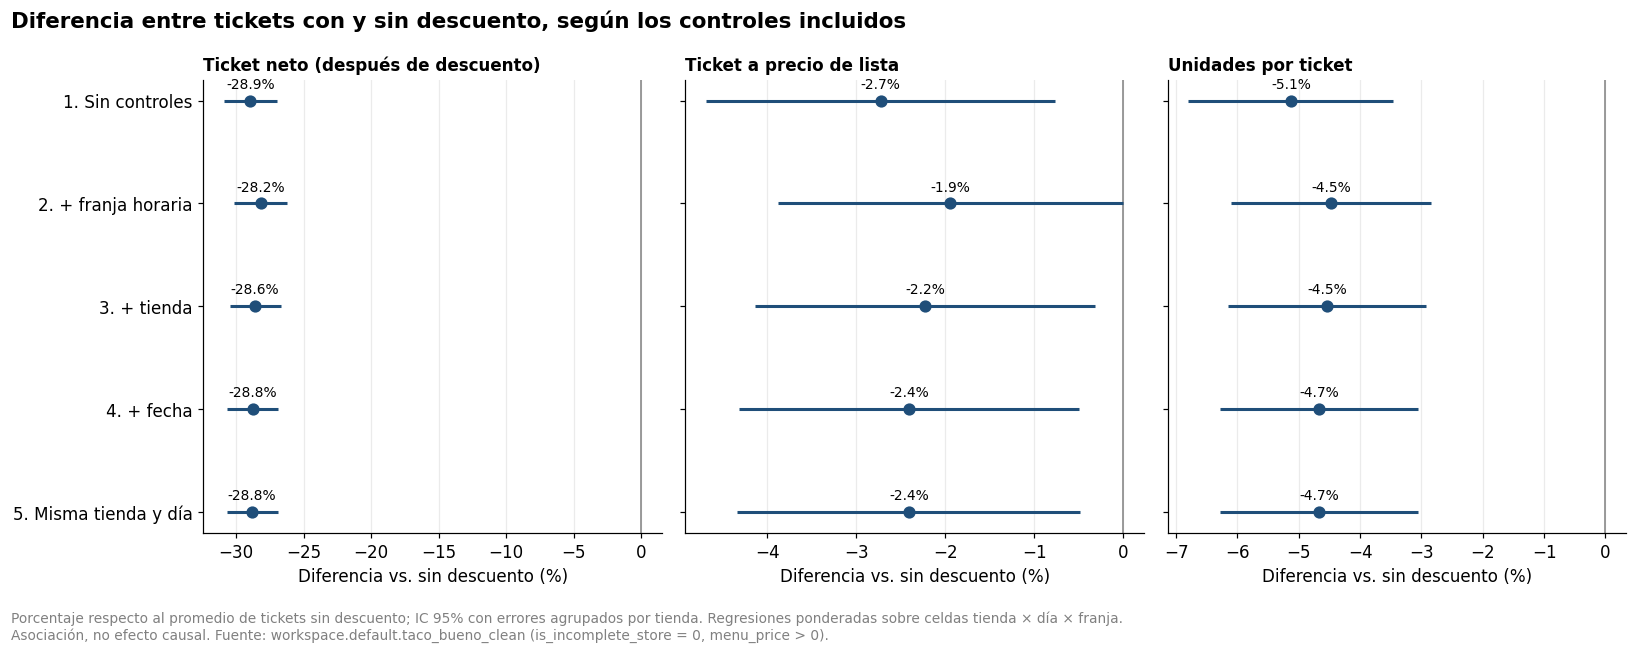

In [0]:
celdas = celdas.assign(ticket_neto=celdas.rev / celdas.n_tickets,
                       ticket_bruto=celdas.gross / celdas.n_tickets,
                       unid_ticket=celdas.units / celdas.n_tickets,
                       fecha=celdas.order_date.dt.strftime("%Y-%m-%d"))

specs = {"1. Sin controles":      "",
         "2. + franja horaria":   " | time_period",
         "3. + tienda":           " | time_period + store_number",
         "4. + fecha":            " | time_period + store_number + fecha",
         "5. Misma tienda y día": " | time_period + store_number^fecha"}
etiquetas_y = {"ticket_neto": "Ticket neto (después de descuento)",
               "ticket_bruto": "Ticket a precio de lista",
               "unid_ticket": "Unidades por ticket"}

filas = []
for y in etiquetas_y:
    sin = celdas[celdas.con_desc == 0]
    base_y = wmean(sin[y], sin.n_tickets)
    for s, fe in specs.items():
        fit = pf.feols(f"{y} ~ con_desc{fe}", data=celdas, weights="n_tickets", vcov={"CRV1": "store_number"})
        filas.append(dict(variable=y, especificacion=s, coef=fit.coef()["con_desc"],
                          se=fit.se()["con_desc"], base=base_y))
res_desc = pd.DataFrame(filas)
res_desc["pct"] = 100 * res_desc.coef / res_desc.base
res_desc["lo"]  = 100 * (res_desc.coef - 1.96 * res_desc.se) / res_desc.base
res_desc["hi"]  = 100 * (res_desc.coef + 1.96 * res_desc.se) / res_desc.base
display(res_desc.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
etiquetas_spec = list(specs)[::-1]
for ax, (y, titulo) in zip(axes, etiquetas_y.items()):
    r = res_desc[res_desc.variable == y].set_index("especificacion").loc[etiquetas_spec]
    pos = np.arange(len(r))
    ax.axvline(0, color="grey", lw=1)
    ax.hlines(pos, r.lo, r.hi, color=AZUL, lw=2)
    ax.plot(r.pct, pos, "o", color=AZUL, ms=7)
    for p, v in zip(pos, r.pct):
        ax.annotate(f"{v:+.1f}%", (v, p), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax.set_yticks(pos, etiquetas_spec)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("Diferencia vs. sin descuento (%)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Diferencia entre tickets con y sin descuento, según los controles incluidos",
             x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.text(0.01, -0.06, "Porcentaje respecto al promedio de tickets sin descuento; IC 95% con errores agrupados por tienda. "
         "Regresiones ponderadas sobre celdas tienda × día × franja.\nAsociación, no efecto causal. " + FUENTE,
         color="grey", fontsize=9)
fig.tight_layout()
guardar(fig, "impacto_promociones.png")

### Interpretación: tickets con y sin descuento

El **7.2%** de los tickets tiene algún descuento. En total, los descuentos equivalen al **1.9%** del ingreso a precio de lista, con un promedio de USD 3.64 por ticket con descuento.

**Resultados de las regresiones:**

- **Ticket neto:** los tickets con descuento son **28.9% menores** sin controles y **28.8% menores** comparando dentro de la misma tienda y el mismo día. El coeficiente casi no cambia al agregar controles, por lo que la diferencia **no se explica** por la tienda, el día ni la franja horaria.
- **Unidades por ticket:** los tickets con descuento tienen solo **4.7% menos** unidades.
- **Ticket a precio de lista (panel central):** compara cuánto valen ambas canastas antes de aplicar el descuento.

**Conclusión:** quien usa un descuento compra prácticamente la misma cantidad de productos que quien no lo usa, pero paga bastante menos. Casi toda la diferencia en el ticket neto es el propio descuento. Es decir, **el descuento no agranda la canasta**: en el corto plazo funciona como un subsidio al cliente, no como un motor de ventas.

**Limitaciones:**
- Es una **asociación, no un efecto causal**: el cliente decide si usa el descuento.
- Las regresiones controlan por tienda, fecha y franja, pero **no por canal**. Como los descuentos se concentran en la app móvil (ver siguiente gráfica), parte de la diferencia podría deberse al canal.
- No sabemos si el descuento atrae **clientes nuevos** que no habrían venido; para eso se necesita un experimento (sección 9).

**Cómo leerlo.** El salto entre la fila 1 y la fila 5 es el tamaño del sesgo por composición: cuánto de la diferencia "con vs. sin descuento" se explica solo por en qué tiendas, días y horarios se usan los descuentos. Lo que queda en la fila 5 compara tickets de la misma tienda el mismo día; aun así puede reflejar selección (quien pide más es quien califica para la promoción), no el efecto de la promoción sobre el comportamiento.

## 5. Factores de confusión: ¿dónde y cuándo se concentran los descuentos?

Si los descuentos se usaran al azar, la proporción de tickets con descuento sería parecida en todas las franjas, días, canales y tiendas. Las diferencias muestran qué variables hay que controlar (o diseñar) en una evaluación seria.

time_period,tickets,pct
Dinner,1676485,0.061816240527055116
Late Night,83041,0.07377078792403752
Lunch,2109256,0.07463010653993636
Breakfast,799635,0.0757545630193776
Afternoon,1311313,0.08022722263868352


dia,tickets,pct
Lun,938060,0.07687674562394729
Mar,913840,0.07213078875952027
Mié,919195,0.06937265759713662
Jue,958349,0.06843853335267215
Vie,737953,0.07266858458465512
Sáb,681688,0.07465145345084555
Dom,830645,0.07349950941738047


channel,tickets,pct
Online: GrubHub,8295,0.0
Online: UberEats,84174,0.0
Online: DoorDash,302655,3.304092118088252E-6
To Go,45884,0.0385537442245663
Drive Thru,3972845,0.047369328529051596
Inside,14422,0.09665788378865622
Carry Out,449538,0.11689556833905031
3,5518,0.1362812613265676
Dine-In,1067901,0.16752957437065796
Online,26461,0.33056195910963304


Entre tiendas: p10 = 4.0%, mediana = 6.8%, p90 = 10.9%


con_desc_0,con_desc_1
0.6823158746061001,0.43466842821276214
0.16027253304035838,0.4132203726501491
0.07157111237751221,0.12137345162176957
0.003193566281824562,0.020203116735534803
0.007953267275753108,0.004085893849909805
0.0023487513559676187,0.003219749025875788
8.592377158843775E-4,0.00173690908712955
9.879611168792255E-5,0.0014897690973385102
0.05456393866203743,2.30971953075738E-6
0.0014954630409695577,null


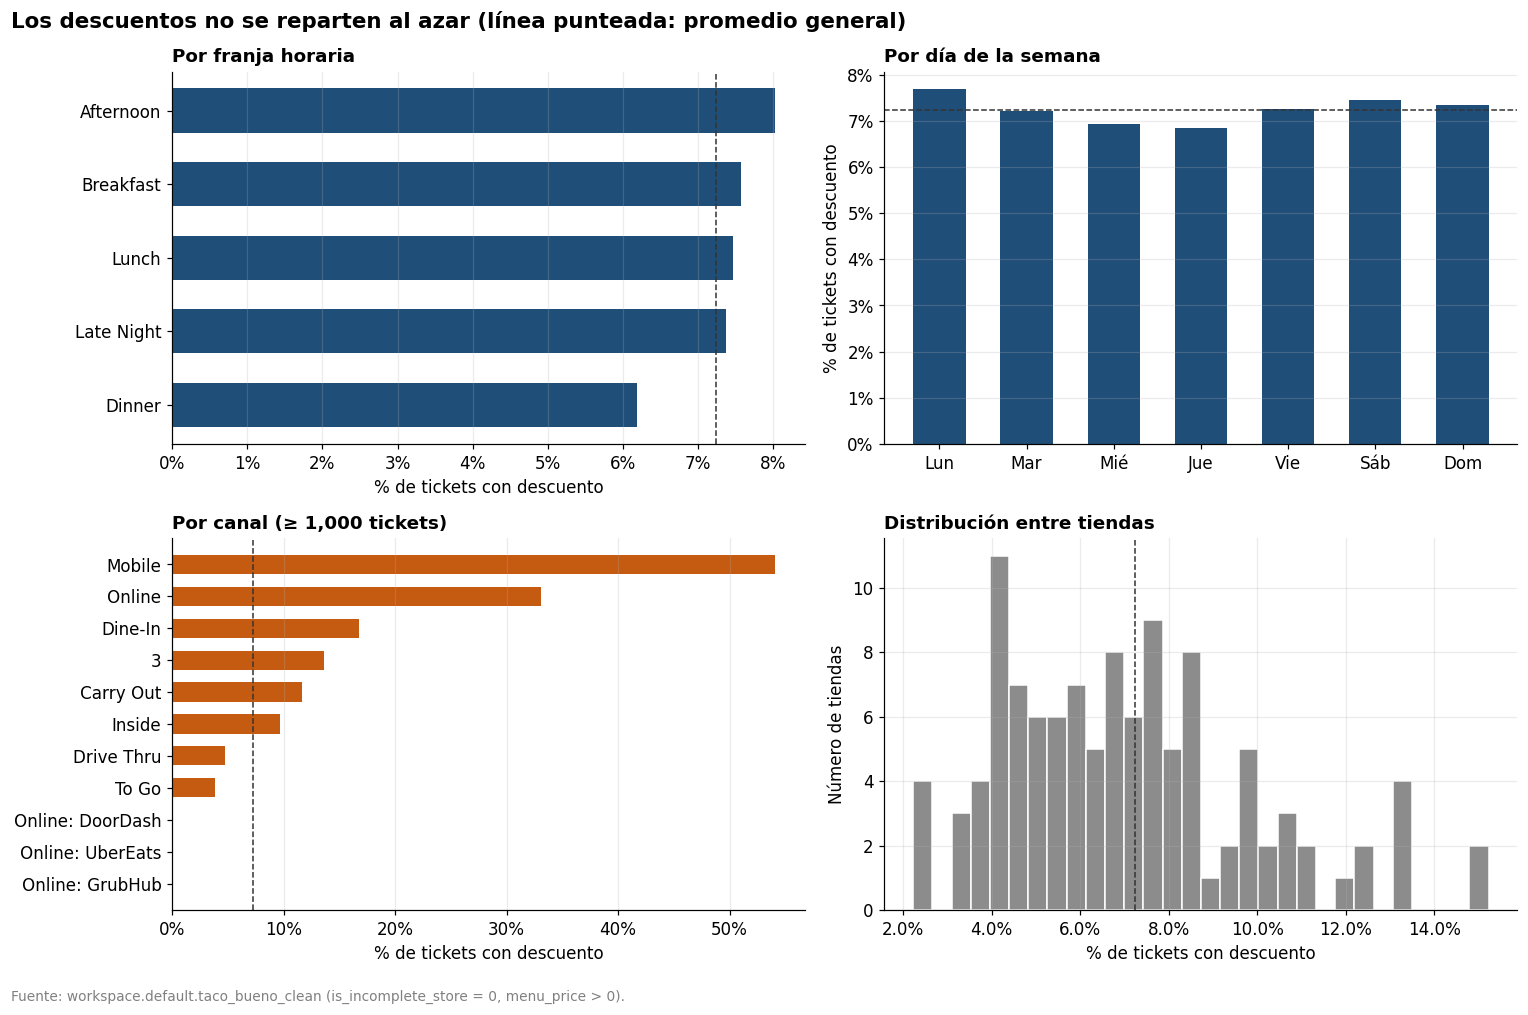

In [0]:
def pct_desc(dat, por):
    t = (dat.assign(nd=dat.n_tickets * dat.con_desc).groupby(por)
         .agg(tickets=("n_tickets", "sum"), nd=("nd", "sum")).reset_index())
    t["pct"] = t.nd / t.tickets
    return t.drop(columns="nd")

f_periodo = pct_desc(celdas, "time_period").sort_values("pct")
f_dia     = pct_desc(celdas.assign(dia=celdas.order_date.dt.dayofweek), "dia").sort_values("dia")
f_dia["dia"] = [DIAS[i] for i in f_dia.dia]
f_canal   = pct_desc(canal, "channel").query("tickets >= 1000").sort_values("pct")
f_tienda  = pct_desc(celdas, "store_number").query("tickets >= 1000")
display(f_periodo); display(f_dia); display(f_canal)
print(f"Entre tiendas: p10 = {100 * f_tienda.pct.quantile(.1):.1f}%, mediana = {100 * f_tienda.pct.median():.1f}%, "
      f"p90 = {100 * f_tienda.pct.quantile(.9):.1f}%")

# Mezcla de canales en tickets con y sin descuento
mezcla_canal = (canal.groupby(["channel", "con_desc"]).n_tickets.sum()
                .groupby(level="con_desc").transform(lambda s: s / s.sum())
                .unstack("con_desc").add_prefix("con_desc_").sort_values("con_desc_1", ascending=False))
display(mezcla_canal)

fig, axs = plt.subplots(2, 2, figsize=(14, 9))
(a1, a2), (a3, a4) = axs
a1.barh(f_periodo.time_period, f_periodo.pct, color=AZUL, height=0.6)
a1.set_title("Por franja horaria")
a2.bar(f_dia.dia, f_dia.pct, color=AZUL, width=0.6)
a2.set_title("Por día de la semana")
a3.barh(f_canal.channel, f_canal.pct, color=NARANJA, height=0.6)
a3.set_title("Por canal (≥ 1,000 tickets)")
a4.hist(f_tienda.pct, bins=30, color=GRIS, edgecolor="white")
a4.set_title("Distribución entre tiendas")
a4.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
a4.set_ylabel("Número de tiendas")
for ax in (a1, a3, a4):
    ax.axvline(pct_tickets_desc, ls="--", color="#333333", lw=1)
    if ax is not a4:
        ax.xaxis.set_major_formatter(PCT)
    ax.set_xlabel("% de tickets con descuento")
for ax in (a1, a3):
    ax.grid(axis="y", visible=False)
a2.axhline(pct_tickets_desc, ls="--", color="#333333", lw=1)
a2.yaxis.set_major_formatter(PCT)
a2.set_ylabel("% de tickets con descuento")
a2.grid(axis="x", visible=False)
fig.suptitle("Los descuentos no se reparten al azar (línea punteada: promedio general)",
             x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.text(0.01, -0.02, FUENTE, color="grey", fontsize=9)
fig.tight_layout()
guardar(fig, "factores_confusion.png")

In [0]:
# ¿Qué tanto de la variación en el uso de descuentos explica cada dimensión?
# R² ponderado de la proporción de tickets con descuento (celda tienda × día × franja) sobre efectos fijos,
# calculado con demeaning alternado (equivale a una regresión sobre dummies de cada dimensión).
cel_share = (celdas.assign(nd=celdas.n_tickets * celdas.con_desc)
             .groupby(["store_number", "fecha", "time_period"])
             .agg(n=("n_tickets", "sum"), nd=("nd", "sum")).reset_index())
cel_share["pct"] = cel_share.nd / cel_share.n

def r2_efectos_fijos(dat, y, w, fes, tol=1e-10, max_iter=500):
    resid = dat[y].to_numpy(float).copy()
    wts = dat[w].to_numpy(float)
    ybar = np.sum(wts * resid) / wts.sum()
    sst = np.sum(wts * (resid - ybar) ** 2)
    codigos = [pd.factorize(dat[fe])[0] for fe in fes]
    for _ in range(max_iter):
        cambio = 0.0
        for cod in codigos:
            medias = np.bincount(cod, wts * resid) / np.bincount(cod, wts)
            resid = resid - medias[cod]
            cambio = max(cambio, np.abs(medias).max())
        if cambio < tol:
            break
    return 1 - np.sum(wts * resid ** 2) / sst

r2_fe = {nombre: r2_efectos_fijos(cel_share, "pct", "n", fes) for nombre, fes in {
    "Tienda": ["store_number"], "Fecha": ["fecha"], "Franja horaria": ["time_period"],
    "Tienda + fecha + franja": ["store_number", "fecha", "time_period"]}.items()}
display(pd.Series(r2_fe, name="R²").round(3).to_frame())

R²
0.233
0.013
0.014
0.26


**Cómo leerlo.** Un R² alto para *tienda* indica que el uso de descuentos depende sobre todo de la sucursal (política local, ubicación, perfil de clientes); uno alto para *fecha* apunta a campañas o calendario. En ambos casos, comparar tickets "con vs. sin" entre tiendas o entre semanas confunde el efecto de la promoción con esas diferencias.

### Interpretación: factores de confusión

Si los descuentos se aplicaran al azar, el porcentaje de tickets con descuento sería parecido en todas las categorías. Los datos muestran que no es así:

| Dimensión | Rango del % de tickets con descuento | Lectura |
|---|---|---|
| Franja horaria | 6.2% (Dinner) a 8.0% (Afternoon) | Diferencias pequeñas |
| Día de la semana | Cercano al promedio todos los días | Sin patrón fuerte |
| Canal | 0.0% (Online: GrubHub) a **54.1% (Mobile)** | **Diferencia enorme** |
| Tienda | Variación amplia entre sucursales | La tienda explica un **R² de 0.23** |
| Fecha | — | La fecha explica un **R² de solo 0.01** |

**Conclusión:** los descuentos **no dependen del horario ni de la fecha**, sino del **canal** y de la **sucursal**. Más de la mitad de los pedidos por app móvil tienen descuento, lo que convierte a la app en el principal canal de promociones. Como la fecha casi no explica nada, no se observan campañas concentradas en días específicos: los descuentos parecen ser permanentes de la app o decisiones de cada tienda.

**Implicación para evaluar promociones:** cualquier comparación entre tickets, tiendas o periodos con y sin descuento debe controlar por **canal** y **tienda**; de lo contrario, el efecto de la promoción se confunde con el tipo de cliente y la sucursal.

**Nota sobre los datos:** el 0% en GrubHub probablemente no significa que no haya descuentos en esa plataforma, sino que los descuentos de plataformas externas **no se registran** en el punto de venta.

## 6. Precios entre tiendas y elasticidad exploratoria

Para los 40 artículos con más ventas: (a) qué tanto varía el precio de lista del mismo artículo entre tiendas en el mismo mes; (b) qué tan seguido cambia; (c) una **elasticidad exploratoria**: regresión de log(unidades por día) sobre log(precio) con efectos fijos artículo × tienda y artículo × mes, es decir, usando solo cambios de precio propios de cada tienda. Es una cifra para generar hipótesis, no un parámetro causal: las tiendas pueden cambiar precios justamente cuando cambia su demanda.

In [0]:
its = item_tienda_mes[item_tienda_mes.units >= 20].assign(
    p_lista=lambda x: x.gross / x.units, p_neto=lambda x: x.rev / x.units)

disp = (its.groupby(["menu_item", "periodo"]).p_lista
        .agg(n_tiendas="size", media="mean", sd="std", mx="max", mn="min").reset_index()
        .query("n_tiendas >= 10"))
disp["cv"] = disp.sd / disp.media
disp["ratio_max_min"] = disp.mx / disp.mn
disp_item = (disp.groupby("menu_item")
             .agg(cv_mediano=("cv", "median"), ratio_max_min_mediano=("ratio_max_min", "median"))
             .sort_values("cv_mediano", ascending=False))
display(disp_item)

its = its.sort_values(["store_number", "menu_item", "periodo"])
its["cambio"] = (its.p_lista / its.groupby(["store_number", "menu_item"]).p_lista.shift() - 1).abs()
pct_cambio = (its.cambio.dropna() > 0.02).mean()
print(f"CV mediano del precio entre tiendas: {100 * disp.cv.median():.1f}% | Observaciones tienda-artículo "
      f"con cambio de precio > 2% vs. mes anterior: {100 * pct_cambio:.1f}%")

el = (its.merge(dias_tm, on=["store_number", "periodo"])
      .query("dias_tienda >= 15 and p_neto > 0")
      .assign(log_q=lambda x: np.log(x.units / x.dias_tienda),
              log_p_lista=lambda x: np.log(x.p_lista), log_p_neto=lambda x: np.log(x.p_neto),
              mes_str=lambda x: x.periodo.dt.strftime("%Y-%m")))
e_lista = pf.feols("log_q ~ log_p_lista | menu_item^store_number + menu_item^mes_str", data=el, vcov={"CRV1": "store_number"})
e_neto  = pf.feols("log_q ~ log_p_neto  | menu_item^store_number + menu_item^mes_str", data=el, vcov={"CRV1": "store_number"})
e_lista.summary(); e_neto.summary()
el_coef = e_lista.coef()["log_p_lista"]

cv_mediano,ratio_max_min_mediano
0.15080921452553314,2.5899158006981344
0.04701294583881013,1.272020960873665
0.026409716407255243,1.1381049829258127
0.02498059759871852,1.1358034936309698
0.023220251425312876,1.1461800510599653
0.022723073495658674,1.1215365136814415
0.02129553084941828,1.143971856824574
0.020943931667622415,1.1188572800384107
0.019845170267772553,1.104890694493362
0.01749209193604602,1.0894455828240963


CV mediano del precio entre tiendas: 1.4% | Observaciones tienda-artículo con cambio de precio > 2% vs. mes anterior: 21.7%
###

Estimation:  OLS
Dep. var.: log_q, Fixed effects: menu_item^store_number + menu_item^mes_str
sample: None = all
Inference:  CRV1
Observations:  39340

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_p_lista   |      0.237 |        0.037 |     6.454 |      0.000 |  0.164 |   0.309 |
---
RMSE: 0.115 R2: 0.988 R2 Within: 0.007 
###

Estimation:  OLS
Dep. var.: log_q, Fixed effects: menu_item^store_number + menu_item^mes_str
sample: None = all
Inference:  CRV1
Observations:  39340

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_p_neto    |      0.101 |        0.024 |     4.191 |      0.000 |

/local_disk0/.ephemeral_nfs/envs/pythonEnv-5238ef6c-f757-4c19-837a-9f08c787804f/lib/python3.12/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 12 singleton fixed effect(s) dropped from the model.
  warnings.warn(
/local_disk0/.ephemeral_nfs/envs/pythonEnv-5238ef6c-f757-4c19-837a-9f08c787804f/lib/python3.12/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 12 singleton fixed effect(s) dropped from the model.
  warnings.warn(


### Interpretación: precios y elasticidad

- **Precios casi iguales entre tiendas:** el precio de lista del mismo producto varía apenas **1.4%** (coeficiente de variación mediano) entre sucursales. Los precios los fija el corporativo.
- **Cambios frecuentes en el tiempo:** **21.7%** de las observaciones tienda-producto-mes muestran un cambio de precio mayor a 2% respecto al mes anterior, consistente con los aumentos de menú que explican el +3.7% de precio puro.
- **Elasticidad de +0.24:** el signo positivo no tiene sentido económico (implicaría que subir el precio aumenta las ventas). Esto indica que **la elasticidad no se puede identificar con estos datos**: como los precios casi no varían entre tiendas, la poca variación que queda coincide con cambios en la demanda (endogeneidad).

**Conclusión:** con datos observacionales no es posible medir cuánto responden los clientes al precio. Esto refuerza la necesidad de un **experimento** o de cambios de precio escalonados entre tiendas para estimar la sensibilidad al precio de forma confiable.

## 7. Síntesis de negocio

La siguiente celda redacta la síntesis con las cifras calculadas arriba, para copiarla al README o al reporte final.

In [0]:
fp = lambda x: f"{x:+.1f}%"
cp = componentes.set_index("componente").pct
comp_max = cp.abs().idxmax()
pick = lambda v, s: res_desc.query("variable == @v and especificacion == @s").pct.iloc[0]
ing = pick("ticket_neto", "1. Sin controles")
fin = pick("ticket_neto", "5. Misma tienda y día")
uni = pick("unid_ticket", "5. Misma tienda y día")
top_p, bot_p = f_periodo.iloc[-1], f_periodo.iloc[0]
top_c, bot_c = f_canal.iloc[-1], f_canal.iloc[0]

print(f"""1. Dinámica del negocio. Entre {meses_completos[0]:%B %Y} y {meses_completos[-1]:%B %Y}, en {len(tiendas_bal)} tiendas comparables, el ingreso neto por tienda-día cambió {fp(100 * acum.d_ingreso)}. Por componente: tickets por tienda-día {fp(cp.iloc[0])}, unidades por ticket {fp(cp.iloc[1])}, precio de lista puro {fp(cp.iloc[2])}, mezcla de productos {fp(cp.iloc[3])} y descuentos {fp(cp.iloc[4])}. El componente dominante fue «{comp_max}».

2. Peso de los descuentos. {100 * pct_tickets_desc:.1f}% de los tickets tiene algún descuento; en total equivalen a {100 * pct_desc_bruto:.2f}% del ingreso a precio de lista (promedio de ${desc_prom:.2f} por ticket con descuento).

3. Con vs. sin descuento. Sin controles, el ticket neto con descuento difiere {fp(ing)} del ticket sin descuento; comparando dentro de la misma tienda y el mismo día la diferencia es {fp(fin)}, y en unidades por ticket {fp(uni)}. La distancia entre ambas cifras es sesgo por composición, y lo que queda sigue siendo asociación, no efecto causal.

4. Factores de confusión. El uso de descuentos va de {100 * bot_p.pct:.1f}% ({bot_p.time_period}) a {100 * top_p.pct:.1f}% ({top_p.time_period}) entre franjas, y de {100 * bot_c.pct:.1f}% ({bot_c.channel}) a {100 * top_c.pct:.1f}% ({top_c.channel}) entre canales. Los efectos fijos de tienda explican un R² de {r2_fe['Tienda']:.2f} de la variación entre celdas; los de fecha, {r2_fe['Fecha']:.2f}.

5. Precios. El precio de lista del mismo artículo varía entre tiendas con un coeficiente de variación mediano de {100 * disp.cv.median():.1f}%, y {100 * pct_cambio:.1f}% de las observaciones tienda-artículo-mes muestran un cambio mayor a 2% respecto al mes anterior. La elasticidad exploratoria al precio de lista es {el_coef:.2f} (no causal).""")

1. Dinámica del negocio. Entre January 2026 y September 2026, en 112 tiendas comparables, el ingreso neto por tienda-día cambió +9.7%. Por componente: tickets por tienda-día +6.0%, unidades por ticket -0.7%, precio de lista puro +3.7%, mezcla de productos +1.3% y descuentos -0.6%. El componente dominante fue «Tickets por tienda-día».

2. Peso de los descuentos. 7.2% de los tickets tiene algún descuento; en total equivalen a 1.90% del ingreso a precio de lista (promedio de $3.64 por ticket con descuento).

3. Con vs. sin descuento. Sin controles, el ticket neto con descuento difiere -28.9% del ticket sin descuento; comparando dentro de la misma tienda y el mismo día la diferencia es -28.8%, y en unidades por ticket -4.7%. La distancia entre ambas cifras es sesgo por composición, y lo que queda sigue siendo asociación, no efecto causal.

4. Factores de confusión. El uso de descuentos va de 6.2% (Dinner) a 8.0% (Afternoon) entre franjas, y de 0.0% (Online: GrubHub) a 54.1% (Mobile) entre 

## 8. Hipótesis para la siguiente fase

Cada hipótesis sale de un patrón de las secciones anteriores y se puede refutar con datos adicionales.

**H1. Los tickets con descuento son más grandes por diseño, no por efecto de la promoción.** Si la mayoría de los descuentos son de combo o con mínimo de compra, la diferencia en unidades por ticket es mecánica. *Prueba:* con el tipo de descuento, comparar descuentos condicionados vs. no condicionados.

**H2. Las promociones redistribuyen demanda en el tiempo y entre productos más que crearla.** Parte de los tickets con descuento habrían ocurrido de todos modos (otro día o a precio completo): *pull-forward* y canibalización. *Prueba:* estudio de eventos con rezagos posteriores a la promoción (¿hay una caída después?) y ventas de artículos sustitutos.

**H3. El uso de descuentos depende de la tienda y del canal, no solo de la oferta.** La concentración por canal y por sucursal (sección 5) sugiere que la política local o el canal digital determinan quién recibe descuentos. *Prueba:* con el calendario oficial de promociones, separar promociones corporativas de descuentos discrecionales.

**H4. El crecimiento de ingresos depende más de precio que de tráfico (o al revés).** La descomposición de la sección 3 indica cuál; la hipótesis económica es que, si domina el precio con tickets estables o a la baja, el margen de maniobra para más aumentos es limitado. *Prueba:* elasticidades por categoría con variación de precios plausiblemente exógena (cambios corporativos escalonados).

**H5. La respuesta al precio es heterogénea entre tiendas.** La dispersión de precios entre sucursales permite estimar si las tiendas con precios más altos pierden volumen. *Prueba:* interacción de la elasticidad con características de la tienda (ubicación, competencia cercana, ingreso de la zona).

## 9. Propuesta para evaluar promociones

**Pregunta de evaluación.** ¿Cuánto ingreso y margen **adicional** genera una promoción, comparado con lo que habría pasado sin ella?

**Métrica de éxito.** No basta con más tickets o más unidades. Lo relevante es el margen incremental:

$$\Delta \text{Margen} = \underbrace{\Delta Q \times m}_{\text{ventas nuevas}} \; - \; \underbrace{d \times Q_0}_{\text{subsidio a quien ya compraba}} \; - \; \text{canibalización} \; + \; \text{efecto halo}$$

donde $m$ es el margen unitario, $d$ el descuento y $Q_0$ las unidades que se habrían vendido de todas formas.

**Diseño recomendado, en orden de preferencia:**

1. **Experimento por tienda.** Asignar la promoción al azar a un grupo de tiendas, estratificando por tamaño, región y canal predominante (las variables que la sección 5 mostró como confusoras). Con ~100 tiendas el poder estadístico es limitado, así que conviene estratificar y usar varias semanas pre-tratamiento como control.
2. **Diferencias en diferencias con adopción escalonada.** Si la promoción ya se lanzó en distintas fechas por tienda: unidad tienda-semana, efectos fijos de tienda y de semana, y estimadores robustos a efectos heterogéneos (Callaway & Sant'Anna; Sun & Abraham). En Python, `pyfixest` incluye estimadores de estudio de eventos.
3. **Estudio de eventos** con 4–6 semanas antes y después para revisar tendencias previas paralelas (supuesto clave) y la caída posterior a la promoción (*pull-forward*).

**Resultados a medir:** tickets por tienda-día, unidades y ingreso del producto promocionado, ingreso de sustitutos (canibalización) y complementos (halo), ticket neto, margen bruto y nuevos vs. recurrentes si hay identificador de cliente.

**Controles y validaciones:** día de la semana, franja horaria y canal (sección 5), clima y eventos locales, pruebas placebo con fechas falsas, y errores agrupados por tienda.

## 10. Datos adicionales necesarios y limitaciones

**Datos que faltan para pasar de asociación a efecto causal**

| Dato | Para qué |
|---|---|
| Calendario de promociones (inicio, fin, tiendas, mecánica, producto) | Definir tratamiento y fechas; separar promociones corporativas de descuentos discrecionales |
| Tipo y código del descuento (combo, cupón, app, empleado) | Distinguir descuentos condicionados (H1) |
| Costo unitario o margen por producto | Medir margen incremental, no solo ingreso |
| Identificador de cliente o programa de lealtad | Separar clientes nuevos de recurrentes; medir *pull-forward* individual |
| Características de tienda (ubicación, formato, competencia cercana) | Estratificar, controlar y estudiar heterogeneidad (H5) |
| Clima, días festivos y eventos locales | Controles de demanda |
| Precios de la competencia | Interpretar cambios de precio y elasticidad |

**Limitaciones de este análisis**

- Todas las comparaciones son descriptivas: el uso de descuentos es una elección del cliente o de la tienda, no una asignación aleatoria.
- El filtro `menu_price > 0` excluye componentes de combo con precio cero; las unidades por ticket cuentan artículos con precio, no piezas físicas.
- La definición de "ticket con descuento" combina descuentos por artículo y por ticket; si algún tipo de descuento se registra de otra forma en la base cruda, queda fuera.
- El índice de precios usa precios promedio por artículo de todas las tiendas, por lo que incluye cambios en qué tiendas venden cada artículo.
- La elasticidad usa precio realizado a nivel tienda-mes y puede estar sesgada hacia cero por endogeneidad y error de medición.